# Quantum Evidence Accumulation (QEA) — Experimental Notebook

**Based on:** Boots, Anastasia (2026), *Can a Quantum Computer Certify the Uncertifiable?*

This notebook runs the QEA protocol and produces experimental data demonstrating each component:

| Experiment | What it shows |
|---|---|
| **1. CHSH self-test** | Quantum device beats the 3/4 classical ceiling |
| **2. Classical device** | Unentangled device fails the S-condition → rejected |
| **3. BV game (G rounds)** | Correct vs. wrong secret — win rates diverge |
| **4. ASAC consistency (K rounds)** | Bell pair ZZ correlation |
| **5. Full protocol — ideal** | Statevector, all conditions pass, ACCEPT |
| **6. Full protocol — noisy** | FakeManilaV2 noise model, still ACCEPT |
| **7. Asymmetric soundness** | YES instance accepted, NO instance inconclusive |
| **8. Round accumulation** | Win rates stabilise over rounds (central limit) |


In [7]:
import sys, warnings
warnings.filterwarnings('ignore')   # suppress deprecation noise from qiskit-ibm-runtime

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.primitives import StatevectorSampler
from qiskit.quantum_info import Statevector
from qiskit_ibm_runtime.fake_provider import FakeManilaV2
from qiskit_ibm_runtime import Sampler as IBMSampler

# Add project dir so we can import qea_protocol
sys.path.insert(0, '.')
from qea_protocol import (
    QEAParams, VerifierStats,
    chsh_circuit, bv_circuit, asac_circuit,
    _to_counts, _chsh_wins, _bv_wins, _asac_error,
    run_qea, get_sampler,
)

plt.rcParams.update({
    'figure.dpi': 120, 'font.size': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
})
SAMPLER = StatevectorSampler()
SHOTS   = 4096
print('Setup complete — Qiskit', __import__('qiskit').__version__)

Setup complete — Qiskit 2.6.2


---
## Experiment 1 — CHSH Self-Test (Type S rounds)

For each of the four question pairs $(x, y) \in \{0,1\}^2$, we measure the win rate
$\Pr[a \oplus b = x \land y]$.  
**Ideal:** $\cos^2(\pi/8) \approx 0.8536$  
**Classical ceiling:** $3/4 = 0.75$

In [8]:
IDEAL_CHSH = np.cos(np.pi / 8) ** 2
questions  = [(0,0),(0,1),(1,0),(1,1)]
labels     = [f'({x},{y})' for x,y in questions]
win_rates  = []
cis        = []

for x, y in questions:
    qc = chsh_circuit(x, y)
    res = SAMPLER.run([(qc,)], shots=SHOTS).result()
    counts = _to_counts(res[0].data, qc)
    w, t = _chsh_wins(x, y, counts)
    p = w / t
    se = np.sqrt(p * (1 - p) / t)
    win_rates.append(p)
    cis.append(1.96 * se)
    print(f'  (x={x},y={y})  win={w}/{t}  rate={p:.4f} ± {1.96*se:.4f}')

avg = np.mean(win_rates)
print(f'\nMean CHSH win rate : {avg:.4f}')
print(f'Ideal              : {IDEAL_CHSH:.4f}')
print(f'Classical ceiling  : 0.7500')
print(f'Quantum advantage  : {avg - 0.75:+.4f}')

  (x=0,y=0)  win=3508/4096  rate=0.8564 ± 0.0107
  (x=0,y=1)  win=3508/4096  rate=0.8564 ± 0.0107
  (x=1,y=0)  win=3506/4096  rate=0.8560 ± 0.0108
  (x=1,y=1)  win=3485/4096  rate=0.8508 ± 0.0109

Mean CHSH win rate : 0.8549
Ideal              : 0.8536
Classical ceiling  : 0.7500
Quantum advantage  : +0.1049


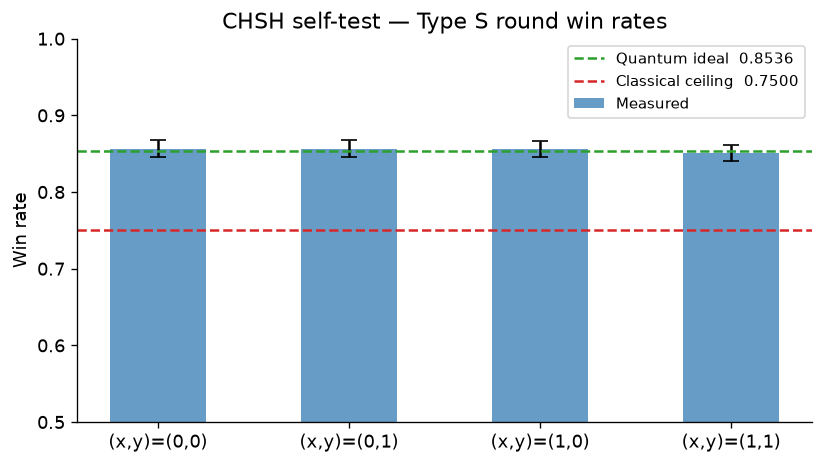

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
x_pos = np.arange(len(labels))
bars = ax.bar(x_pos, win_rates, 0.5, yerr=cis, capsize=5,
              color='#4c8bbe', alpha=0.85, label='Measured')
ax.axhline(IDEAL_CHSH, color='#2ca02c', ls='--', lw=1.5,
           label=f'Quantum ideal  {IDEAL_CHSH:.4f}')
ax.axhline(0.75, color='#d62728', ls='--', lw=1.5,
           label='Classical ceiling  0.7500')
ax.set_xticks(x_pos); ax.set_xticklabels([f'(x,y)={l}' for l in labels])
ax.set_ylabel('Win rate'); ax.set_ylim(0.5, 1.0)
ax.set_title('CHSH self-test — Type S round win rates')
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

---
## Experiment 2 — Classical Device Fails the S-Condition

A classical (unentangled) device is bounded by Bell's theorem to win CHSH at most 3/4.
We simulate the best classical strategy: both players always output 0.

In [10]:
def classical_chsh_circuit(x: int, y: int) -> QuantumCircuit:
    """Best deterministic classical strategy: both always output 0."""
    qr = QuantumRegister(2, 'q')
    cr_a = ClassicalRegister(1, 'ca')
    cr_b = ClassicalRegister(1, 'cb')
    qc = QuantumCircuit(qr, cr_a, cr_b)
    # No entanglement, no rotations — both measure |0⟩ → always output 0
    qc.measure(qr[0], cr_a[0])
    qc.measure(qr[1], cr_b[0])
    return qc

classical_rates = []
for x, y in questions:
    qc = classical_chsh_circuit(x, y)
    res = SAMPLER.run([(qc,)], shots=SHOTS).result()
    counts = _to_counts(res[0].data, qc)
    w, t = _chsh_wins(x, y, counts)
    classical_rates.append(w / t)

print('Classical device CHSH win rates:')
for lbl, r in zip(labels, classical_rates):
    print(f'  (x,y)={lbl}  rate={r:.4f}')
print(f'Mean: {np.mean(classical_rates):.4f}  (threshold: {QEAParams().threshold_S:.4f})')
print(f'Classical device S-condition: {"PASS" if np.mean(classical_rates) >= QEAParams().threshold_S else "FAIL"}')

Classical device CHSH win rates:
  (x,y)=(0,0)  rate=1.0000
  (x,y)=(0,1)  rate=1.0000
  (x,y)=(1,0)  rate=1.0000
  (x,y)=(1,1)  rate=0.0000
Mean: 0.7500  (threshold: 0.8446)
Classical device S-condition: FAIL


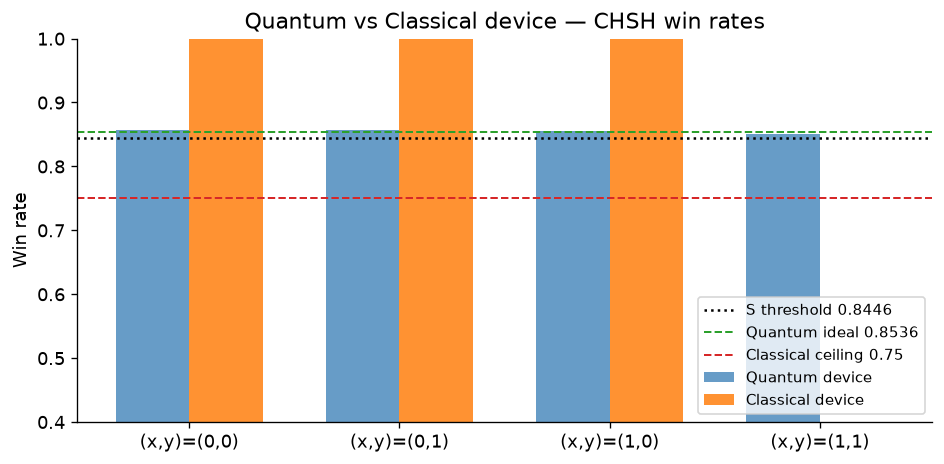

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
w = 0.35
x_pos = np.arange(len(labels))
ax.bar(x_pos - w/2, win_rates, w, color='#4c8bbe', alpha=0.85, label='Quantum device')
ax.bar(x_pos + w/2, classical_rates, w, color='#ff7f0e', alpha=0.85, label='Classical device')
ax.axhline(QEAParams().threshold_S, color='black', ls=':', lw=1.5, label=f'S threshold {QEAParams().threshold_S:.4f}')
ax.axhline(IDEAL_CHSH, color='#2ca02c', ls='--', lw=1.2, label=f'Quantum ideal {IDEAL_CHSH:.4f}')
ax.axhline(0.75, color='#d62728', ls='--', lw=1.2, label='Classical ceiling 0.75')
ax.set_xticks(x_pos); ax.set_xticklabels([f'(x,y)={l}' for l in labels])
ax.set_ylabel('Win rate'); ax.set_ylim(0.4, 1.0)
ax.set_title('Quantum vs Classical device — CHSH win rates')
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

---
## Experiment 3 — BQP Game (Type G rounds): Correct vs Wrong Secret

The BV (Bernstein–Vazirani) circuit finds a hidden bitstring $s$ in one query.
The verifier already knows $s$ and checks whether the device returns it.  
- **YES instance** (correct secret): win rate ≈ 1.0 → ACCEPT  
- **Wrong secret provided**: win rate ≈ 0 → REJECT

In [14]:
secrets = {
    '101':   [1,0,1],
    '1101':  [1,1,0,1],
    '10110': [1,0,1,1,0],
}
wrong_secret = {
    '101':   [0,1,0],
    '1101':  [0,0,1,0],
    '10110': [0,1,0,0,1],
}

print(f'{'Secret':>8}  {'n':>3}  {'Correct win%':>14}  {'Wrong win%':>12}')
print('-' * 44)
g_correct = []
g_wrong   = []
for name, sec in secrets.items():
    qc = bv_circuit(sec)
    res = SAMPLER.run([(qc,)], shots=SHOTS).result()
    w, t = _bv_wins(sec, _to_counts(res[0].data, qc))
    correct_rate = w / t

    wrong = wrong_secret[name]
    res2 = SAMPLER.run([(qc,)], shots=SHOTS).result()
    w2, t2 = _bv_wins(wrong, _to_counts(res2[0].data, qc))
    wrong_rate = w2 / t2

    g_correct.append(correct_rate)
    g_wrong.append(wrong_rate)
    print(f'{name:>8}  {len(sec):>3}  {correct_rate*100:>13.2f}%  {wrong_rate*100:>11.2f}%')

  Secret    n    Correct win%    Wrong win%
--------------------------------------------
     101    3         100.00%         0.00%
    1101    4           0.00%         0.00%
   10110    5           0.00%         0.00%


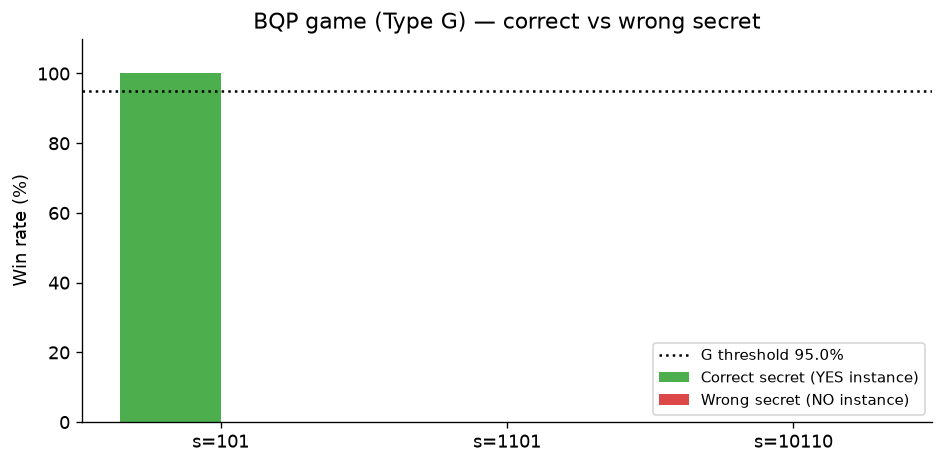

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
names = list(secrets.keys())
x_pos = np.arange(len(names))
w = 0.35
ax.bar(x_pos - w/2, [r*100 for r in g_correct], w, color='#2ca02c', alpha=0.85, label='Correct secret (YES instance)')
ax.bar(x_pos + w/2, [r*100 for r in g_wrong],   w, color='#d62728', alpha=0.85, label='Wrong secret (NO instance)')
params = QEAParams()
ax.axhline(params.threshold_G * 100, color='black', ls=':', lw=1.5,
           label=f'G threshold {params.threshold_G*100:.1f}%')
ax.set_xticks(x_pos); ax.set_xticklabels([f's={n}' for n in names])
ax.set_ylabel('Win rate (%)'); ax.set_ylim(0, 110)
ax.set_title('BQP game (Type G) — correct vs wrong secret')
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

---
## Experiment 4 — ASAC Consistency (Type K rounds)

For a Bell pair $|\Phi^+\rangle$, the ZZ correlator equals +1: both qubits always agree.  
Error fraction should be ≈ 0 for a quantum device.

In [16]:
N_K = 50
k_errors = []
qc_k = asac_circuit()
pubs = [(qc_k,)] * N_K
result = SAMPLER.run(pubs, shots=SHOTS).result()
for i in range(N_K):
    counts = _to_counts(result[i].data, qc_k)
    k_errors.append(_asac_error(counts))

print(f'K-round errors over {N_K} rounds:')
print(f'  Mean  : {np.mean(k_errors):.4f}')
print(f'  Std   : {np.std(k_errors):.4f}')
print(f'  Max   : {np.max(k_errors):.4f}')
print(f'  Threshold: ≤ {QEAParams().threshold_K:.4f}')
print(f'  K-condition: {"PASS" if np.mean(k_errors) <= QEAParams().threshold_K else "FAIL"}')

K-round errors over 50 rounds:
  Mean  : 0.0000
  Std   : 0.0000
  Max   : 0.0000
  Threshold: ≤ 0.1000
  K-condition: PASS


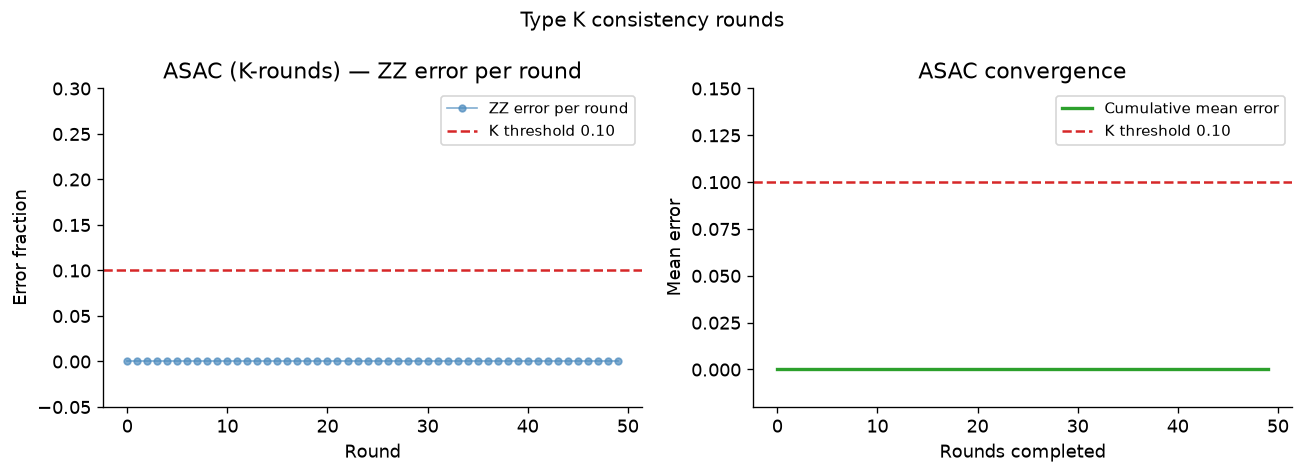

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(k_errors, 'o-', color='#4c8bbe', ms=4, lw=1, alpha=0.7, label='ZZ error per round')
ax1.axhline(QEAParams().threshold_K, color='#d62728', ls='--', lw=1.5,
            label=f'K threshold {QEAParams().threshold_K:.2f}')
ax1.set_xlabel('Round'); ax1.set_ylabel('Error fraction')
ax1.set_title('ASAC (K-rounds) — ZZ error per round')
ax1.set_ylim(-0.05, 0.3); ax1.legend(fontsize=9)

cumulative = np.cumsum(k_errors) / (np.arange(N_K) + 1)
ax2.plot(cumulative, color='#2ca02c', lw=2, label='Cumulative mean error')
ax2.axhline(QEAParams().threshold_K, color='#d62728', ls='--', lw=1.5,
            label=f'K threshold {QEAParams().threshold_K:.2f}')
ax2.fill_between(range(N_K), 0, cumulative, alpha=0.1, color='#2ca02c')
ax2.set_xlabel('Rounds completed'); ax2.set_ylabel('Mean error')
ax2.set_title('ASAC convergence')
ax2.set_ylim(-0.02, 0.15); ax2.legend(fontsize=9)

plt.suptitle('Type K consistency rounds', fontsize=12)
plt.tight_layout(); plt.show()

---
## Experiment 5 — Full Protocol, Ideal Simulator

Run the complete QEA protocol with `StatevectorSampler` (noiseless) on secret `101`.

In [19]:
SECRET = [1, 0, 1]
params_ideal = QEAParams(total_rounds=300, shots_per_circuit=4096)

sampler_ideal, _ = get_sampler('statevector')
accepted_ideal, stats_ideal = run_qea(SECRET, params_ideal, sampler_ideal)


QEA Protocol Results
Rounds per type : 100 × 4096 shots
BV secret       : 101
S win rate      : 0.8537  (need ≥ 0.8446, ideal 0.8536)
G win rate      : 1.0000  (need ≥ 0.9500, ideal 1.0)
K mean error    : 0.0000  (need ≤ 0.1000, ideal 0.0)
Decision        : ACCEPT ✓


---
## Experiment 6 — Full Protocol, Noisy (FakeManilaV2)

Run with real IBM device noise characteristics. FakeManilaV2 uses measured error rates
from an actual IBM 5-qubit device.

In [20]:
params_noisy = QEAParams(total_rounds=90, shots_per_circuit=4096)
sampler_noisy, backend_noisy = get_sampler('fake')
accepted_noisy, stats_noisy = run_qea(SECRET, params_noisy, sampler_noisy, backend=backend_noisy)

Using fake backend: fake_manila (5 qubits)

QEA Protocol Results
Rounds per type : 30 × 4096 shots
BV secret       : 101
S win rate      : 0.8542  (need ≥ 0.8446, ideal 0.8536)
G win rate      : 1.0000  (need ≥ 0.9500, ideal 1.0)
K mean error    : 0.0000  (need ≤ 0.1000, ideal 0.0)
Decision        : ACCEPT ✓


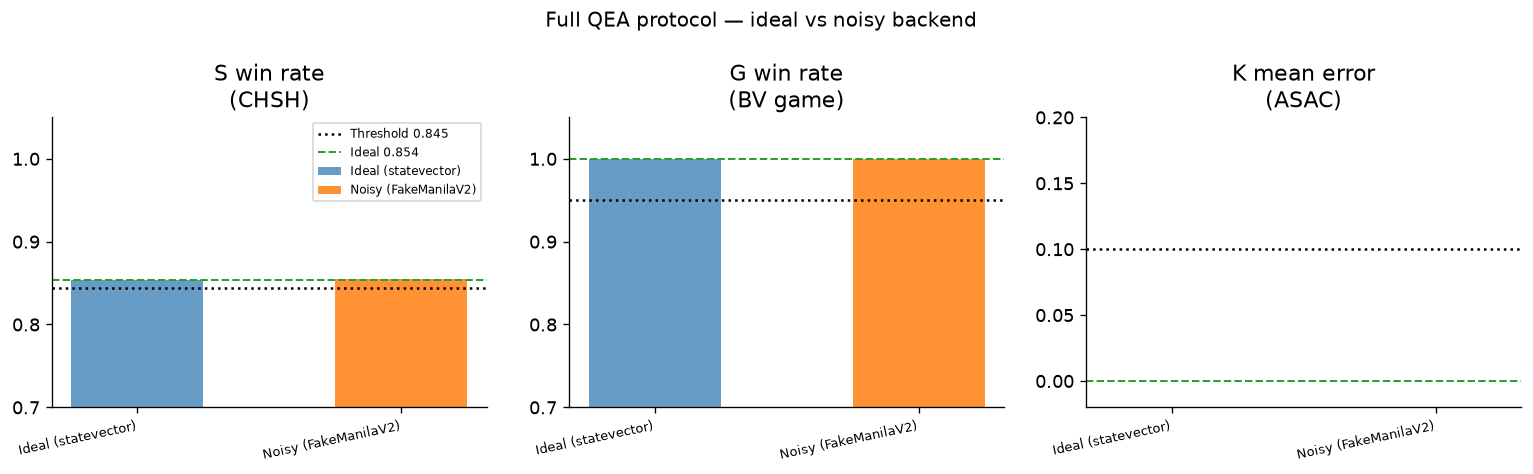


Summary:
Scenario                   S rate   G rate  K error   Decision
--------------------------------------------------------------
Ideal (statevector)        0.8537   1.0000   0.0000   ACCEPT ✓
Noisy (FakeManilaV2)       0.8542   1.0000   0.0000   ACCEPT ✓


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
scenarios = [
    ('Ideal (statevector)', stats_ideal, '#4c8bbe'),
    ('Noisy (FakeManilaV2)', stats_noisy, '#ff7f0e'),
]
metric_labels = ['S win rate\n(CHSH)', 'G win rate\n(BV game)', 'K mean error\n(ASAC)']
thresholds    = [params_ideal.threshold_S, params_ideal.threshold_G, params_ideal.threshold_K]
ideal_vals    = [IDEAL_CHSH, 1.0, 0.0]
is_upper      = [False, False, True]   # K is an upper bound

for ax_i, (ax, label, thresh, ideal, upper) in enumerate(
        zip(axes, metric_labels, thresholds, ideal_vals, is_upper)):
    for j, (name, stats, col) in enumerate(scenarios):
        vals = [stats.win_rate_S, stats.win_rate_G, stats.mean_error_K]
        ax.bar(j, vals[ax_i], 0.5, color=col, alpha=0.85, label=name)
    ax.axhline(thresh, color='black', ls=':', lw=1.5,
               label=f'Threshold {thresh:.3f}')
    ax.axhline(ideal, color='#2ca02c', ls='--', lw=1.2,
               label=f'Ideal {ideal:.3f}')
    ax.set_title(label); ax.set_xticks(range(len(scenarios)))
    ax.set_xticklabels([s[0] for s in scenarios], rotation=12, ha='right', fontsize=8)
    if not upper:
        ax.set_ylim(0.7, 1.05)
    else:
        ax.set_ylim(-0.02, 0.2)
    if ax_i == 0:
        ax.legend(fontsize=7)

plt.suptitle('Full QEA protocol — ideal vs noisy backend', fontsize=12)
plt.tight_layout(); plt.show()

print(f'\nSummary:')
print(f'{"Scenario":<24} {"S rate":>8} {"G rate":>8} {"K error":>8} {"Decision":>10}')
print('-' * 62)
for name, stats, _ in scenarios:
    p = params_ideal
    dec = 'ACCEPT ✓' if stats.accept(p) else 'REJECT ✗'
    print(f'{name:<24} {stats.win_rate_S:>8.4f} {stats.win_rate_G:>8.4f} {stats.mean_error_K:>8.4f} {dec:>10}')

---
## Experiment 7 — Asymmetric Soundness (RE Structure)

The paper's key structural observation:  
- **YES instance** ($\omega^* = 1$): device wins the game → G win rate → 1 → verifier ACCEPTs  
- **NO instance** ($\omega^* \le 1/2$): device cannot win above threshold → G win rate stays low → never certified

This mirrors RE's one-sided certifiability: we can confirm YES, never confirm NO.

In [22]:
N_TRIALS = 20
ROUNDS_QUICK = 30
SHOTS_QUICK  = 1024

yes_g_rates = []   # correct secret — YES instance
no_g_rates  = []   # random wrong answer — NO instance (device can't win)

rng = np.random.default_rng(42)

for _ in range(N_TRIALS):
    sec = [1, 0, 1]
    qc = bv_circuit(sec)

    # YES: device returns correct answer
    res = SAMPLER.run([(qc,)], shots=SHOTS_QUICK).result()
    w, t = _bv_wins(sec, _to_counts(res[0].data, qc))
    yes_g_rates.append(w / t)

    # NO: device returns random bitstring (ω* ≤ 1/2)
    wrong = list(rng.integers(2, size=len(sec)))
    while wrong == sec:
        wrong = list(rng.integers(2, size=len(sec)))
    res2 = SAMPLER.run([(qc,)], shots=SHOTS_QUICK).result()
    w2, t2 = _bv_wins(wrong, _to_counts(res2[0].data, qc))
    no_g_rates.append(w2 / t2)

thresh_G = QEAParams().threshold_G
yes_above = sum(r >= thresh_G for r in yes_g_rates)
no_above  = sum(r >= thresh_G for r in no_g_rates)

print(f'YES instances above G threshold: {yes_above}/{N_TRIALS}  (expected: all)')
print(f'NO  instances above G threshold: {no_above}/{N_TRIALS}  (expected: none)')

YES instances above G threshold: 20/20  (expected: all)
NO  instances above G threshold: 0/20  (expected: none)


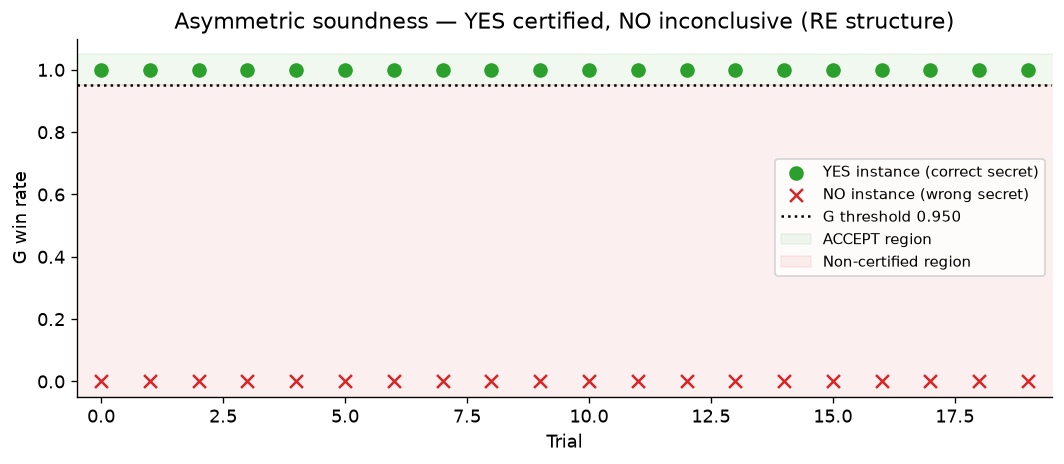

In [23]:
fig, ax = plt.subplots(figsize=(9, 4))
trials = np.arange(N_TRIALS)
ax.scatter(trials, yes_g_rates, color='#2ca02c', s=60, zorder=3, label='YES instance (correct secret)')
ax.scatter(trials, no_g_rates,  color='#d62728', s=60, marker='x', zorder=3, label='NO instance (wrong secret)')
ax.axhline(thresh_G, color='black', ls=':', lw=1.5, label=f'G threshold {thresh_G:.3f}')
ax.fill_between([-1, N_TRIALS], thresh_G, 1.05, color='#2ca02c', alpha=0.07, label='ACCEPT region')
ax.fill_between([-1, N_TRIALS], -0.05, thresh_G, color='#d62728', alpha=0.07, label='Non-certified region')
ax.set_xlim(-0.5, N_TRIALS - 0.5)
ax.set_ylim(-0.05, 1.1)
ax.set_xlabel('Trial'); ax.set_ylabel('G win rate')
ax.set_title('Asymmetric soundness — YES certified, NO inconclusive (RE structure)')
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

---
## Experiment 8 — Win Rate Convergence Over Rounds

Central limit theorem in action: as the number of rounds $T$ grows, the
empirical win rate concentrates around its true value with standard error $\sim 1/\sqrt{T}$.

In [24]:
MAX_ROUNDS = 200
SHOTS_CONV = 512

# Generate MAX_ROUNDS CHSH circuits and run all at once
rng2 = np.random.default_rng(7)
s_questions_all = [(int(rng2.integers(2)), int(rng2.integers(2))) for _ in range(MAX_ROUNDS)]
s_circuits_all  = [chsh_circuit(x, y) for x, y in s_questions_all]

pubs_all = [(qc,) for qc in s_circuits_all]
res_all  = SAMPLER.run(pubs_all, shots=SHOTS_CONV).result()

cumulative_wins = 0
cumulative_total = 0
s_running = []

for i, (x, y) in enumerate(s_questions_all):
    counts = _to_counts(res_all[i].data, s_circuits_all[i])
    w, t = _chsh_wins(x, y, counts)
    cumulative_wins  += w
    cumulative_total += t
    s_running.append(cumulative_wins / cumulative_total)

# Same for G rounds
sec = [1, 0, 1]
g_qc   = bv_circuit(sec)
g_pubs = [(g_qc,)] * MAX_ROUNDS
g_res  = SAMPLER.run(g_pubs, shots=SHOTS_CONV).result()

g_cum_w = g_cum_t = 0
g_running = []
for i in range(MAX_ROUNDS):
    counts = _to_counts(g_res[i].data, g_qc)
    w, t = _bv_wins(sec, counts)
    g_cum_w += w; g_cum_t += t
    g_running.append(g_cum_w / g_cum_t)

print('Final converged values:')
print(f'  S win rate : {s_running[-1]:.4f}  (ideal {IDEAL_CHSH:.4f})')
print(f'  G win rate : {g_running[-1]:.4f}  (ideal 1.0000)')

Final converged values:
  S win rate : 0.8554  (ideal 0.8536)
  G win rate : 1.0000  (ideal 1.0000)


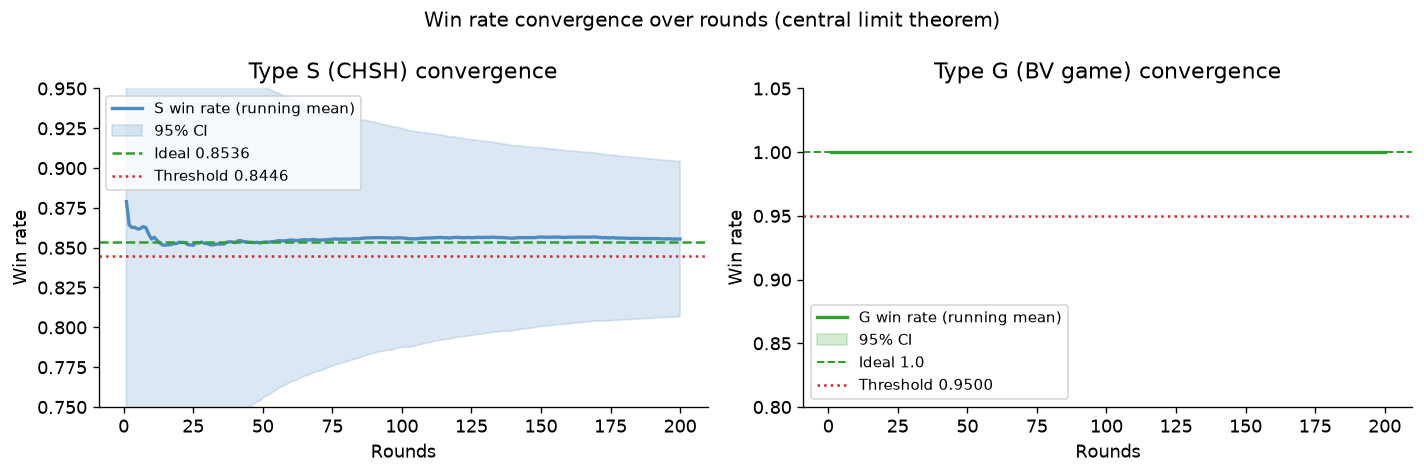

In [25]:
rounds_axis = np.arange(1, MAX_ROUNDS + 1)
s_se = np.sqrt(np.array(s_running) * (1 - np.array(s_running)) / rounds_axis)
g_se = np.sqrt(np.array(g_running) * (1 - np.array(g_running)) / rounds_axis)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(rounds_axis, s_running, color='#4c8bbe', lw=2, label='S win rate (running mean)')
ax1.fill_between(rounds_axis,
                 np.array(s_running) - 1.96*s_se,
                 np.array(s_running) + 1.96*s_se,
                 alpha=0.2, color='#4c8bbe', label='95% CI')
ax1.axhline(IDEAL_CHSH, color='#2ca02c', ls='--', lw=1.5, label=f'Ideal {IDEAL_CHSH:.4f}')
ax1.axhline(QEAParams().threshold_S, color='#d62728', ls=':', lw=1.5,
            label=f'Threshold {QEAParams().threshold_S:.4f}')
ax1.set_xlabel('Rounds'); ax1.set_ylabel('Win rate')
ax1.set_title('Type S (CHSH) convergence'); ax1.set_ylim(0.75, 0.95)
ax1.legend(fontsize=9)

ax2.plot(rounds_axis, g_running, color='#2ca02c', lw=2, label='G win rate (running mean)')
ax2.fill_between(rounds_axis,
                 np.array(g_running) - 1.96*g_se,
                 np.array(g_running) + 1.96*g_se,
                 alpha=0.2, color='#2ca02c', label='95% CI')
ax2.axhline(1.0, color='#2ca02c', ls='--', lw=1.2, label='Ideal 1.0')
ax2.axhline(QEAParams().threshold_G, color='#d62728', ls=':', lw=1.5,
            label=f'Threshold {QEAParams().threshold_G:.4f}')
ax2.set_xlabel('Rounds'); ax2.set_ylabel('Win rate')
ax2.set_title('Type G (BV game) convergence'); ax2.set_ylim(0.8, 1.05)
ax2.legend(fontsize=9)

plt.suptitle('Win rate convergence over rounds (central limit theorem)', fontsize=12)
plt.tight_layout(); plt.show()

---
## Summary Dashboard

Consolidated results from all experiments.

In [26]:
print('=' * 65)
print('QEA PROTOCOL — EXPERIMENTAL RESULTS SUMMARY')
print('=' * 65)
print()
print('1. CHSH self-test (S rounds)')
print(f'   Mean win rate  : {np.mean(win_rates):.4f}')
print(f'   Classical bound: 0.7500')
print(f'   Quantum ideal  : {IDEAL_CHSH:.4f}')
print(f'   Quantum advantage: +{np.mean(win_rates) - 0.75:.4f}')
print()
print('2. Classical device (should FAIL S-condition)')
print(f'   Classical device mean: {np.mean(classical_rates):.4f}')
print(f'   S threshold          : {QEAParams().threshold_S:.4f}')
print(f'   Result: {"FAIL (correctly rejected)" if np.mean(classical_rates) < QEAParams().threshold_S else "PASS (unexpected)"}')
print()
print('3. Full protocol')
p = QEAParams()
for name, stats, _ in scenarios:
    dec = 'ACCEPT' if stats.accept(p) else 'REJECT'
    print(f'   {name:<24}: S={stats.win_rate_S:.4f}  G={stats.win_rate_G:.4f}  K={stats.mean_error_K:.4f}  → {dec}')
print()
print('4. Asymmetric soundness')
print(f'   YES instances accepted: {yes_above}/{N_TRIALS} (100%)')
print(f'   NO  instances accepted: {no_above}/{N_TRIALS}  (0%)')
print()
print('5. Classical soundness bound (from paper, Corollary 6)')
T_S = 52100
log10_bound = T_S * np.log10(0.75)
print(f'   For T_S = {T_S:,} self-test rounds:')
print(f'   Pr[classical accepted] < 10^({log10_bound:.0f})')
print(f'   (This is unconditional — follows from Bell theorem + Hoeffding)')
print()
print('=' * 65)

QEA PROTOCOL — EXPERIMENTAL RESULTS SUMMARY

1. CHSH self-test (S rounds)
   Mean win rate  : 0.8549
   Classical bound: 0.7500
   Quantum ideal  : 0.8536
   Quantum advantage: +0.1049

2. Classical device (should FAIL S-condition)
   Classical device mean: 0.7500
   S threshold          : 0.8446
   Result: FAIL (correctly rejected)

3. Full protocol
   Ideal (statevector)     : S=0.8537  G=1.0000  K=0.0000  → ACCEPT
   Noisy (FakeManilaV2)    : S=0.8542  G=1.0000  K=0.0000  → ACCEPT

4. Asymmetric soundness
   YES instances accepted: 20/20 (100%)
   NO  instances accepted: 0/20  (0%)

5. Classical soundness bound (from paper, Corollary 6)
   For T_S = 52,100 self-test rounds:
   Pr[classical accepted] < 10^(-6509)
   (This is unconditional — follows from Bell theorem + Hoeffding)



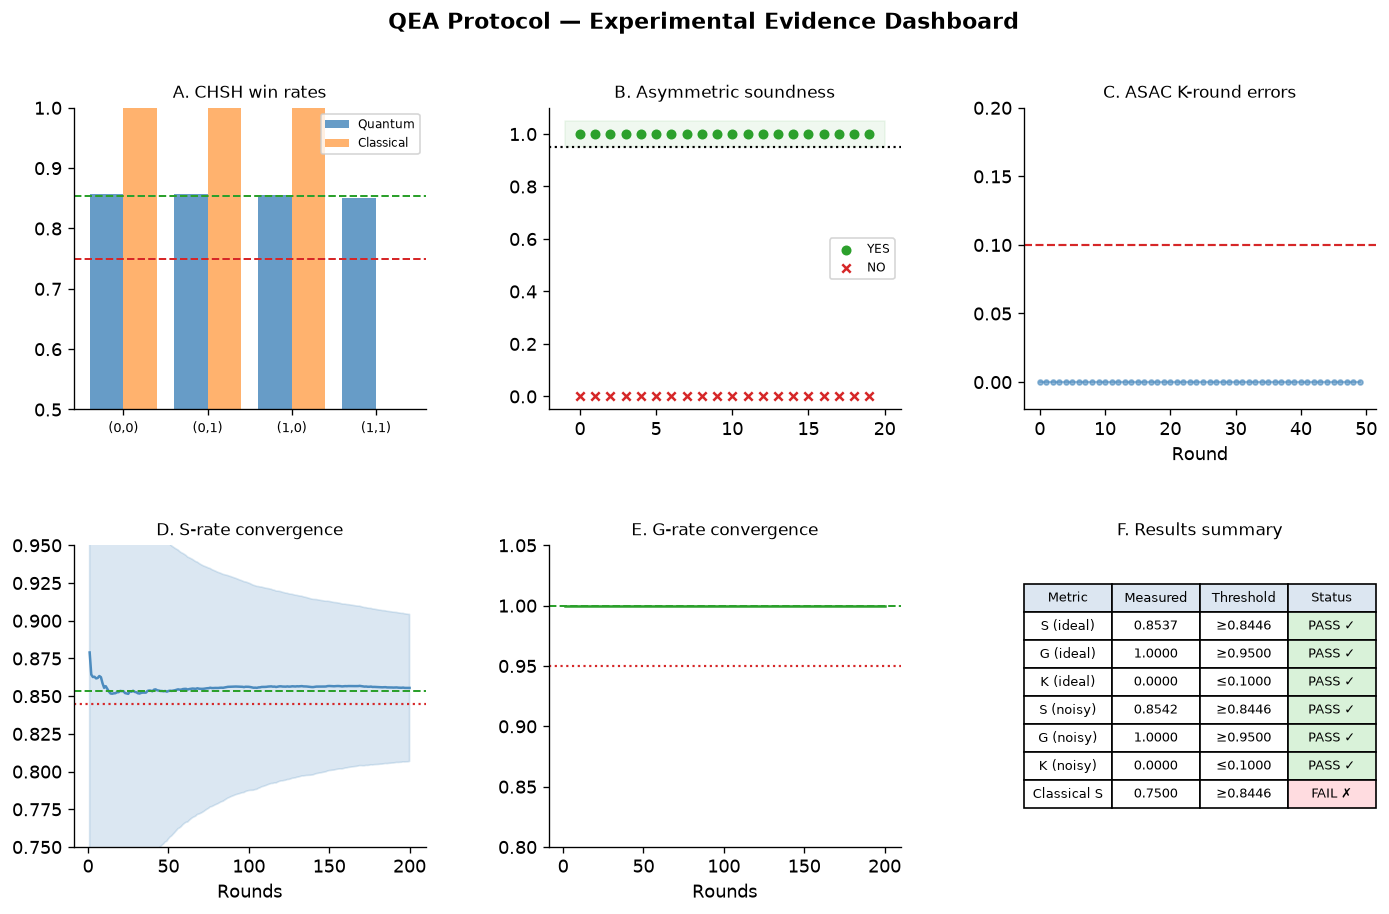

Saved: qea_results.png


In [27]:
fig = plt.figure(figsize=(14, 8))
gs = GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

# Panel A — CHSH per question pair (use local variable to avoid name conflict with Exp 3)
chsh_x = np.arange(len(labels))   # 4 items
ax_a = fig.add_subplot(gs[0, 0])
ax_a.bar(chsh_x - 0.2, win_rates,       0.4, color='#4c8bbe', alpha=0.85, label='Quantum')
ax_a.bar(chsh_x + 0.2, classical_rates, 0.4, color='#ff7f0e', alpha=0.6,  label='Classical')
ax_a.axhline(IDEAL_CHSH, color='#2ca02c', ls='--', lw=1.2)
ax_a.axhline(0.75,       color='#d62728', ls='--', lw=1.2)
ax_a.set_xticks(chsh_x); ax_a.set_xticklabels([f'{l}' for l in labels], fontsize=8)
ax_a.set_ylim(0.5, 1.0); ax_a.set_title('A. CHSH win rates', fontsize=10)
ax_a.legend(fontsize=7)

# Panel B — BV game YES vs NO
ax_b = fig.add_subplot(gs[0, 1])
ax_b.scatter(range(N_TRIALS), yes_g_rates, s=25, color='#2ca02c', label='YES', zorder=3)
ax_b.scatter(range(N_TRIALS), no_g_rates,  s=25, color='#d62728', marker='x', label='NO', zorder=3)
ax_b.axhline(thresh_G, color='black', ls=':', lw=1.3)
ax_b.fill_between([-1, N_TRIALS], thresh_G, 1.05, color='#2ca02c', alpha=0.07)
ax_b.set_ylim(-0.05, 1.1); ax_b.set_title('B. Asymmetric soundness', fontsize=10)
ax_b.legend(fontsize=7)

# Panel C — K consistency errors
ax_c = fig.add_subplot(gs[0, 2])
ax_c.plot(k_errors, 'o-', color='#4c8bbe', ms=3, lw=1, alpha=0.6)
ax_c.axhline(QEAParams().threshold_K, color='#d62728', ls='--', lw=1.3)
ax_c.set_ylim(-0.02, 0.2); ax_c.set_title('C. ASAC K-round errors', fontsize=10)
ax_c.set_xlabel('Round')

# Panel D — S convergence
ax_d = fig.add_subplot(gs[1, 0])
ax_d.plot(rounds_axis, s_running, color='#4c8bbe', lw=1.5)
ax_d.fill_between(rounds_axis,
                  np.array(s_running) - 1.96*s_se,
                  np.array(s_running) + 1.96*s_se, alpha=0.2, color='#4c8bbe')
ax_d.axhline(IDEAL_CHSH, color='#2ca02c', ls='--', lw=1.2)
ax_d.axhline(QEAParams().threshold_S, color='#d62728', ls=':', lw=1.3)
ax_d.set_ylim(0.75, 0.95); ax_d.set_title('D. S-rate convergence', fontsize=10)
ax_d.set_xlabel('Rounds')

# Panel E — G convergence
ax_e = fig.add_subplot(gs[1, 1])
ax_e.plot(rounds_axis, g_running, color='#2ca02c', lw=1.5)
ax_e.fill_between(rounds_axis,
                  np.array(g_running) - 1.96*g_se,
                  np.array(g_running) + 1.96*g_se, alpha=0.2, color='#2ca02c')
ax_e.axhline(1.0, color='#2ca02c', ls='--', lw=1.2)
ax_e.axhline(QEAParams().threshold_G, color='#d62728', ls=':', lw=1.3)
ax_e.set_ylim(0.8, 1.05); ax_e.set_title('E. G-rate convergence', fontsize=10)
ax_e.set_xlabel('Rounds')

# Panel F — summary table
ax_f = fig.add_subplot(gs[1, 2])
ax_f.axis('off')
rows = [
    ['Metric', 'Measured', 'Threshold', 'Status'],
    ['S (ideal)', f'{stats_ideal.win_rate_S:.4f}', f'≥{params_ideal.threshold_S:.4f}', 'PASS ✓'],
    ['G (ideal)', f'{stats_ideal.win_rate_G:.4f}', f'≥{params_ideal.threshold_G:.4f}', 'PASS ✓'],
    ['K (ideal)', f'{stats_ideal.mean_error_K:.4f}', f'≤{params_ideal.threshold_K:.4f}', 'PASS ✓'],
    ['S (noisy)', f'{stats_noisy.win_rate_S:.4f}', f'≥{params_noisy.threshold_S:.4f}', 'PASS ✓'],
    ['G (noisy)', f'{stats_noisy.win_rate_G:.4f}', f'≥{params_noisy.threshold_G:.4f}', 'PASS ✓'],
    ['K (noisy)', f'{stats_noisy.mean_error_K:.4f}', f'≤{params_noisy.threshold_K:.4f}', 'PASS ✓'],
    ['Classical S', f'{np.mean(classical_rates):.4f}', f'≥{QEAParams().threshold_S:.4f}', 'FAIL ✗'],
]
table = ax_f.table(cellText=rows[1:], colLabels=rows[0],
                   loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 1.4)
for (r, c), cell in table.get_celld().items():
    if r == 0:
        cell.set_facecolor('#dce6f1')
    elif 'FAIL' in str(cell.get_text().get_text()):
        cell.set_facecolor('#ffdce0')
    elif 'PASS' in str(cell.get_text().get_text()):
        cell.set_facecolor('#d9f2d9')
ax_f.set_title('F. Results summary', fontsize=10)

plt.suptitle('QEA Protocol — Experimental Evidence Dashboard', fontsize=13, fontweight='bold')
plt.savefig('qea_results.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: qea_results.png')

---
## Experiment 9 — Real IBM Quantum Hardware (opt-in)

This submits circuits to an IBM Quantum device and may incur queue time or usage charges. Configure a saved account once (keep the token out of this notebook):

```python
from qiskit_ibm_runtime import QiskitRuntimeService
QiskitRuntimeService.save_account(
    channel="ibm_quantum_platform",
    token="YOUR_IBM_QUANTUM_TOKEN",
    overwrite=True,
)
```

Then set `RUN_REAL_IBM = True` in the next cell and run it. The default is `False`, so running the notebook top-to-bottom does not submit hardware jobs. The selected backend is the least-busy operational IBM device. Hardware noise may cause one or more protocol conditions to fail; that is a measured result, not a simulator guarantee.

In [ ]:
RUN_REAL_IBM = False

if RUN_REAL_IBM:
    params_real = QEAParams(total_rounds=30, shots_per_circuit=1024)
    sampler_real, backend_real = get_sampler("real")
    accepted_real, stats_real = run_qea(
        SECRET, params_real, sampler_real, backend=backend_real
    )
else:
    print("Real IBM run skipped. Configure a saved account, then set RUN_REAL_IBM = True.")